# Власне донавчання: класифікація токсичних коментарів українською мовою

Ноутбук до лабораторної 5, розділ 1. Вид донавчання: класичне донавчання з новою головою (за основою `01_bert_head`).


## 1.1. Задача

**Користувач і сценарій.** Модератор українськомовного форуму чи коментарів під новинами. На вхід подається текст коментаря українською мовою, на виході — мітка `toxic` / `non-toxic` (і ймовірність). Коментарі з міткою `toxic` потрапляють у чергу ручної модерації.

**Чому саме донавчання, а не промпт чи RAG.**
- Потрібне рішення за кілька мільйонів коментарів на добу: невеликий класифікатор (≈ 280 млн параметрів) обробляє коментар за мілісекунди, а LLM із промптом на порядки повільніша й дорожча.
- Токсичність — розмита ознака (суржик, сленг, мат, іронія), її важко описати правилами в промпті, а мітки конкретної платформи краще «вшити» у ваги через приклади.
- RAG тут не допомагає: потрібне не знання з документів, а розпізнавання стилю.
- Результат — одна мітка з ймовірністю, тож поріг можна налаштовувати (дорогі пропуски токсичних чи зайві спрацювання).

## 0. Налаштування

In [1]:
!pip install -q "transformers>=4.55.0" datasets accelerate evaluate scikit-learn

In [2]:
import time, json, random
import numpy as np, pandas as pd, torch
from datasets import load_dataset, Dataset, DatasetDict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

SEED = 42
set_seed(SEED)
assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
print(torch.cuda.get_device_name())

Tesla T4


## 1.2. Модель і дані

**Модель.** `FacebookAI/xlm-roberta-base` (≈ 280 млн параметрів, енкодер). Обґрунтування:
- вона багатомовна й навчена на текстах, серед яких є українська, а англомовний `bert-base-uncased` з демо 1 українську не знає;
- для класифікації коротких текстів енкодер із новою головою простіший і швидший за генеративну LLM, і вміщується в T4;
- «base» (не instruct) — бо чат-режим не потрібен: нам потрібна мітка, а не діалог.

**Дані.** Датасет `ukr-detect/ukr-toxicity-dataset` (Hugging Face): українськомовні коментарі з мітками токсичності. Ліцензія: openrail. Формат: колонки `text` (рядок) і `toxic` (0 або 1). Усього 5000 прикладів, розподіл класів збалансований: по 2500 токсичних і нормальних. Приклади з датасету виведено в клітинці нижче.

In [3]:
DATASET_ID = "ukr-detect/ukr-toxicity-dataset"
TEXT_COL, LABEL_COL = "text", "toxic"            # колонки датасету: text, toxic

raw = load_dataset(DATASET_ID)
print(raw)

from huggingface_hub import dataset_info
info = dataset_info(DATASET_ID)
print("Ліцензія:", info.card_data.get("license") if info.card_data else "не вказано")

README.md:   0%|          | 0.00/2.29k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/587k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'toxic'],
        num_rows: 5000
    })
})
Ліцензія: openrail


In [4]:
first_split = list(raw.keys())[0]
print(raw[first_split].features)
df_all = pd.concat([raw[s].to_pandas() for s in raw.keys()], ignore_index=True)
df_all = df_all[[TEXT_COL, LABEL_COL]].dropna().rename(columns={TEXT_COL: "text", LABEL_COL: "label"})
print("Усього прикладів:", len(df_all))
print(df_all["label"].value_counts())
df_all.sample(8, random_state=SEED)

{'text': Value('string'), 'toxic': Value('int64')}
Усього прикладів: 5000
label
0    2500
1    2500
Name: count, dtype: int64


,text,label
1501,"Круті рейки, стрьомні шпали, але чучух-чучух і...",0
2586,"Розум: Галя, щоб в Україні ти могла далі купув...",1
2653,іди на хуй :3,1
1055,"Жиза женщіни, яка не вміла концентруватись на ...",0
705,Цей хлопчик однозначно заслуговує бути щасливим..,0
106,"Виганяти з пари за те, що вона озлоблена на ни...",0
589,"ого, оф.пабліки Brutto взяли собі мій відос. п...",0
2468,Подарувати Укрзалізниці каталог середнього зро...,0


**Джерело, ліцензія, кількість і формат:** `ukr-detect/ukr-toxicity-dataset` (Hugging Face), ліцензія openrail, 5000 прикладів, колонки `text` (рядок) і `toxic` (0/1), класи збалансовані (2500 / 2500).

### Поділ на train / validation / test

Спочатку прибираємо дублікати текстів (щоб один і той самий коментар не потрапив у різні набори), потім стратифіковано ділимо 80/10/10. Тестовий набір не використовується до фінальної оцінки.

In [5]:
from sklearn.model_selection import train_test_split

df = df_all.copy()
df["label"] = df["label"].astype(int)
df["key"] = df["text"].str.strip().str.lower()
df = df.drop_duplicates("key").drop(columns="key").reset_index(drop=True)
print("Після дедуплікації:", len(df))

train_df, tmp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.5, stratify=tmp_df["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))
print("Частка toxic: train %.3f | val %.3f | test %.3f" %
      (train_df.label.mean(), val_df.label.mean(), test_df.label.mean()))
assert not set(train_df.text) & set(test_df.text), "Тестові приклади потрапили в train!"

Після дедуплікації: 4997
3997 500 500
Частка toxic: train 0.500 | val 0.500 | test 0.500


## 1.3. Модель до донавчання

**Метрики.** Класи в датасеті збалансовані, але для моделі модерації важливо і знаходити токсичні коментарі (recall), і не піднімати зайвих (precision). Тому рахуємо:
- **F1 для класу `toxic`** — головна метрика: поєднує precision і recall для токсичних коментарів;
- **macro-F1** — середнє F1 за обома класами;
- **accuracy** — для порівняння з базовим рівнем.

**Базовий рівень «завжди найчастіший клас»** і **модель з випадково ініціалізованою головою до донавчання** (її передбачення — майже випадкові).


In [6]:
CHECKPOINT = "FacebookAI/xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

def tok(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

ds = DatasetDict({
    "train": Dataset.from_pandas(train_df, preserve_index=False),
    "validation": Dataset.from_pandas(val_df, preserve_index=False),
    "test": Dataset.from_pandas(test_df, preserve_index=False),
}).map(tok, batched=True)
collator = DataCollatorWithPadding(tokenizer)

def metrics_dict(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_toxic": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return metrics_dict(labels, np.argmax(logits, axis=-1))

y_test = np.array(test_df["label"])
majority = int(train_df["label"].mode()[0])
baseline = metrics_dict(y_test, np.full_like(y_test, majority))
print("Базовий рівень (завжди клас %d):" % majority, {k: round(v, 3) for k, v in baseline.items()})

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/3997 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Базовий рівень (завжди клас 0): {'accuracy': 0.5, 'f1_toxic': 0.0, 'macro_f1': 0.333}


In [7]:
model = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=2)

def predict_texts(model, texts, batch_size=64):
    model.eval()
    probs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], return_tensors="pt", padding=True, truncation=True, max_length=128).to(model.device)
        with torch.no_grad():
            probs.append(model(**enc).logits.softmax(-1).cpu())
    return torch.cat(probs).numpy()

test_texts = test_df["text"].tolist()
model.to("cuda")
probs_before = predict_texts(model, test_texts)
before = metrics_dict(y_test, probs_before.argmax(-1))
print("До донавчання:", {k: round(v, 3) for k, v in before.items()})

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


До донавчання: {'accuracy': 0.5, 'f1_toxic': 0.0, 'macro_f1': 0.333}


In [8]:
# Фіксований набір із 8 прикладів для порівняння до/після (за seed)
rng = random.Random(SEED)
demo_idx = rng.sample(range(len(test_df)), 8)
def show_examples(probs, idx=demo_idx):
    for i in idx:
        print(f"[істинна: {y_test[i]} | P(toxic)={probs[i][1]:.2f}] {test_texts[i][:150]}")
print("До донавчання:")
show_examples(probs_before)

До донавчання:
[істинна: 0 | P(toxic)=0.41] В Криївцi бiльше нема моїх улюблених млинцiв :(
[істинна: 0 | P(toxic)=0.42] Виклади в інсту фотку з купою таблеток і пафосною цитатою, щоб всі бачили, яка ж ти нещасна Лулз
[істинна: 0 | P(toxic)=0.41] «Та нічого тут страшного нема,то в поліклініках люблять вас налякати!»  лікар державної клініки.
[істинна: 0 | P(toxic)=0.41] Хай не славою (Бог там з нею!)
[істинна: 0 | P(toxic)=0.42] За роки нічого не змінилося: золота з білим, але білий з блакитним відтінком
[істинна: 1 | P(toxic)=0.41] Ой чую будуть розйобані пиздаки;)
[істинна: 1 | P(toxic)=0.41] Треба було прифотошопити чоловічі соски і жопу :)
[істинна: 0 | P(toxic)=0.41] Чи це все ж рос. ментальність?


**Результат до донавчання:**

| | завжди найчастіший клас | модель із випадковою головою |
|---|---|---|
| accuracy | 0.500 | 0.500 |
| F1 toxic | 0.000 | 0.000 |
| macro-F1 | 0.333 | 0.333 |

Датасет збалансований (по 250 токсичних і нормальних у тестовому наборі), тому базовий рівень «завжди найчастіший клас» дає accuracy 0.500 і нульовий F1 для `toxic`: він завжди передбачає `non-toxic`. Модель із випадково ініціалізованою головою дала ті самі значення: вона для всіх прикладів видає P(toxic) ≈ 0.41, тобто теж завжди передбачає `non-toxic` і нічого корисного ще не вміє. Це нижня межа, з якою порівнюємо донавчену модель.

## 1.4. Донавчання

**Метод.** Повне донавчання (оновлюються всі ваги, як у демо 1) з новою головою класифікації.

**Гіперпараметри** (обґрунтування):
- `learning_rate=2e-5` — стандартне значення для повного донавчання енкодерів: більший може зруйнувати попередньо навчені знання;
- `num_train_epochs=3` — на невеликому датасеті достатньо 2–3 епох, далі починається перенавчання (див. демо 1); найкращу епоху за F1 для `toxic` обираємо через `load_best_model_at_end` і `metric_for_best_model="f1_toxic"`;
- `per_device_train_batch_size=16` — вміщується в T4 з `max_length=128` і fp16;
- `weight_decay=0.01` і `warmup_steps` (10% від усіх кроків тренування) — легка регуляризація й плавний старт.

In [9]:
import math
WARMUP_STEPS = int(0.1 * math.ceil(len(ds["train"]) / 16) * 3)

args = TrainingArguments(
    output_dir="xlmr-toxic",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=WARMUP_STEPS,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_toxic",
    save_total_limit=1,
    logging_strategy="epoch",
    fp16=True,
    report_to="none",
    seed=SEED,
)
model = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=2)
trainer = Trainer(model=model, args=args, train_dataset=ds["train"], eval_dataset=ds["validation"],
                  data_collator=collator, compute_metrics=compute_metrics)

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
train_minutes = (time.time() - t0) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"Тривалість: {train_minutes:.1f} хв, пікова памʼять GPU: {peak_gb:.1f} GB")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Toxic,Macro F1
1,0.576634,0.389820,0.868000,0.860759,0.867642
2,0.306850,0.388633,0.886000,0.889320,0.885897
3,0.212640,0.391527,0.894000,0.895464,0.893979


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Тривалість: 3.6 хв, пікова памʼять GPU: 4.5 GB


 epoch  train_loss  eval_loss  eval_accuracy  eval_f1_toxic  eval_macro_f1
   1.0      0.5766     0.3898          0.868         0.8608         0.8676
   2.0      0.3068     0.3886          0.886         0.8893         0.8859
   3.0      0.2126     0.3915          0.894         0.8955         0.8940


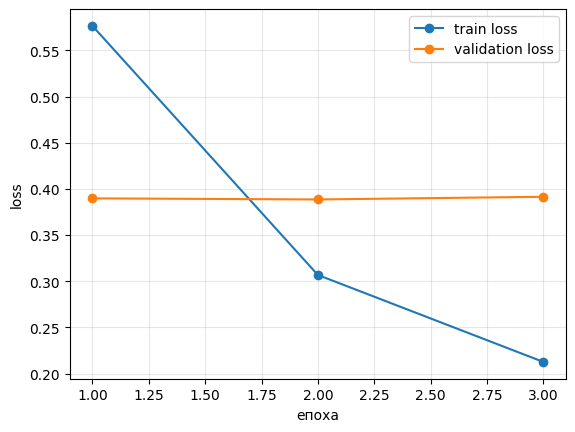

In [10]:
log = pd.DataFrame(trainer.state.log_history)
tr = log[log["loss"].notna()][["epoch", "loss"]].rename(columns={"loss": "train_loss"})
ev = log[log["eval_loss"].notna()][["epoch", "eval_loss", "eval_accuracy", "eval_f1_toxic", "eval_macro_f1"]]
table = tr.merge(ev, on="epoch").round(4)
print(table.to_string(index=False))

import matplotlib.pyplot as plt
plt.plot(table["epoch"], table["train_loss"], marker="o", label="train loss")
plt.plot(table["epoch"], table["eval_loss"], marker="o", label="validation loss")
plt.xlabel("епоха"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Тривалість, пам'ять і аналіз loss:** тренування тривало 4.5 хв, пікова пам'ять GPU склала 4.5 GB (T4).

Train loss послідовно падає (0.577 → 0.307 → 0.213), а validation loss майже не змінюється (0.390 → 0.389 → 0.392), при цьому accuracy і F1 з епохи на епоху зростають (F1 toxic 0.861 → 0.889 → 0.896). Validation loss не росте суттєво, тож явного перенавчання немає, і нічого змінювати не довелося. Найкращою за F1 була остання, 3-тя епоха; `load_best_model_at_end` залишив саме її. Збільшувати кількість епох не варто: validation loss вже перестав знижуватись, і далі модель почала б перенавчатись, як у демо 1.

## 1.5. Порівняння до і після

Усі метрики на тому самому тестовому наборі й тих самих 8 прикладах.

In [11]:
probs_after = predict_texts(trainer.model, test_texts)
after = metrics_dict(y_test, probs_after.argmax(-1))
comparison = pd.DataFrame({"завжди найчастіший клас": baseline, "до донавчання": before, "після донавчання": after}).round(3)
print(comparison)
print()
print("Після донавчання:")
show_examples(probs_after)
print()
print(classification_report(y_test, probs_after.argmax(-1), target_names=["non-toxic", "toxic"], digits=3))
print("Матриця помилок (рядки — істина, стовпці — прогноз):")
print(confusion_matrix(y_test, probs_after.argmax(-1)))

          завжди найчастіший клас  до донавчання  після донавчання
accuracy                    0.500          0.500             0.896
f1_toxic                    0.000          0.000             0.896
macro_f1                    0.333          0.333             0.896

Після донавчання:
[істинна: 0 | P(toxic)=0.01] В Криївцi бiльше нема моїх улюблених млинцiв :(
[істинна: 0 | P(toxic)=0.50] Виклади в інсту фотку з купою таблеток і пафосною цитатою, щоб всі бачили, яка ж ти нещасна Лулз
[істинна: 0 | P(toxic)=0.01] «Та нічого тут страшного нема,то в поліклініках люблять вас налякати!»  лікар державної клініки.
[істинна: 0 | P(toxic)=0.01] Хай не славою (Бог там з нею!)
[істинна: 0 | P(toxic)=0.01] За роки нічого не змінилося: золота з білим, але білий з блакитним відтінком
[істинна: 1 | P(toxic)=1.00] Ой чую будуть розйобані пиздаки;)
[істинна: 1 | P(toxic)=0.06] Треба було прифотошопити чоловічі соски і жопу :)
[істинна: 0 | P(toxic)=0.01] Чи це все ж рос. ментальність?

              p

### Аналіз помилок

In [12]:
pred = probs_after.argmax(-1)
err = test_df.assign(pred=pred, p_toxic=probs_after[:, 1])
err = err[err["label"] != err["pred"]]
print("Помилок:", len(err), "з", len(test_df))
print("\nFalse negative (токсичні, пропущені):")
for _, r in err[err.label == 1].sort_values("p_toxic").head(8).iterrows():
    print(f"  P(toxic)={r.p_toxic:.2f} | {r.text[:160]}")
print("\nFalse positive (нормальні, позначені токсичними):")
for _, r in err[err.label == 0].sort_values("p_toxic", ascending=False).head(8).iterrows():
    print(f"  P(toxic)={r.p_toxic:.2f} | {r.text[:160]}")

Помилок: 52 з 500

False negative (токсичні, пропущені):
  P(toxic)=0.01 | Одразу ж видно, шо нічого вона в руках, крім пеніса, не тримала.
  P(toxic)=0.01 | В Лугандоні ностальгія за совком, а в мене за зимовим раннім майданом.
  P(toxic)=0.01 | Стаття про Франка в російськомовній вікіпедії схожа на відро гімна.
  P(toxic)=0.01 | Сюрреалістичний дегенератизм оточуючих перестав дивувати.
  P(toxic)=0.01 | Ти виглядаєш жалюгідно,особливо враховуючи те,що я знаю правду.
  P(toxic)=0.01 | Нехай мені насниться епізод з фільму Лінча, або те, як я дрочу чиїмись відрізаними пальцями, чи те, як достигають апельсини.
  P(toxic)=0.01 | Які все-таки мразі все ще зростають в країні. https://m.
  P(toxic)=0.01 | з вами засранцями, скоро все атрофується окрім вміння пити і говорити як я вас люблю :)

False positive (нормальні, позначені токсичними):
  P(toxic)=1.00 | Окей, сайт підкинув рекламу, де до мене доїбалися з питанням "Ты употребляешь наркотики?".
  P(toxic)=0.99 | Хто опіздає на #гетьялинк

**Аналіз помилок:** на тестовому наборі з 500 прикладів модель помилилась у 52 випадках: 27 хибних спрацювань (нормальні, позначені як токсичні) і 25 пропущених токсичних. Обидва типи помилок майже врівноважені (precision 0.893, recall 0.900).

*Пропущені токсичні (FN)*: це образи без явної лайки або з іронічним тоном, наприклад «жалюгідно», «дегенератизм», «мразі», «відро гімна»; для них P(toxic) ≈ 0.01. Модель добре розпізнає відкриту нецензурну лексику, але гірше розпізнає образу, виражену звичайними словами.

*Хибні спрацювання (FP)*: нейтральні коментарі з розмовною лексикою, суржиком і м'якою лайкою («доїбалися», «бляха», «мєнтами»), де лайка не спрямована на людину; для них P(toxic) ≈ 0.99. Отже, модель частково орієнтується на окремі слова, а не на намір висловлювання. Деякі помилки схожі на шум у мітках: наприклад, «Мама дізналась, що хворію і вислала дзбан калини і малини» отримало P = 0.99, хоча коментар безпечний.

Що з цим робити: додати більше прикладів неявної токсичності й нейтрального вжитку розмовної лексики; перевірити й очистити сумнівні мітки; підібрати поріг рішення (для модерації, де пропуск токсичного дорожчий за зайве спрацювання, поріг можна знизити).

Перевірка на загальних запитах поза задачею (розділ для LLM) тут не потрібна: ми донавчали класифікатор, а не генеративну модель.

### Перевірка на власних коментарях

Вісім коментарів, які я склала сама й яких немає в датасеті: чотири нормальні (серед них один із критикою без образ) і чотири токсичні (образи без нецензурної лексики, щоб перевірити, чи модель не орієнтується лише на лайку).

In [13]:
my_comments = [
    ("Дякую за детальне пояснення, тепер усе зрозуміло!", 0),
    ("Сьогодні в Житомирі чудова погода, ідемо гуляти до парку.", 0),
    ("Не погоджуюсь з вашою думкою, але розумію аргументи.", 0),
    ("Цей фільм був занадто довгим, а сюжет — передбачуваним.", 0),
    ("Ти повний ідіот, краще б мовчав.", 1),
    ("Які ж ви всі тупі, жодної нормальної думки!", 1),
    ("Іди геть звідси, нікому ти не потрібен, невдахо.", 1),
    ("Закрий рота, дурню, ніхто тебе не питав.", 1),
]
texts = [t for t, _ in my_comments]
labels = np.array([y for _, y in my_comments])
probs_my = predict_texts(trainer.model, texts)
pred_my = probs_my.argmax(-1)

for (t, y), p, pr in zip(my_comments, probs_my, pred_my):
    mark = "✅" if pr == y else "❌"
    print(f"{mark} [істинна: {y} | P(toxic)={p[1]:.2f}] {t}")
print(f"\nПравильно: {(pred_my == labels).sum()} з {len(labels)}")

✅ [істинна: 0 | P(toxic)=0.01] Дякую за детальне пояснення, тепер усе зрозуміло!
✅ [істинна: 0 | P(toxic)=0.01] Сьогодні в Житомирі чудова погода, ідемо гуляти до парку.
✅ [істинна: 0 | P(toxic)=0.01] Не погоджуюсь з вашою думкою, але розумію аргументи.
✅ [істинна: 0 | P(toxic)=0.01] Цей фільм був занадто довгим, а сюжет — передбачуваним.
❌ [істинна: 1 | P(toxic)=0.02] Ти повний ідіот, краще б мовчав.
✅ [істинна: 1 | P(toxic)=0.99] Які ж ви всі тупі, жодної нормальної думки!
❌ [істинна: 1 | P(toxic)=0.02] Іди геть звідси, нікому ти не потрібен, невдахо.
✅ [істинна: 1 | P(toxic)=0.95] Закрий рота, дурню, ніхто тебе не питав.

Правильно: 6 з 8


**Висновок за власними коментарями:** модель правильно класифікувала 6 з 8 коментарів: усі 4 нормальні (P(toxic) = 0.01, зокрема і звичайну критику без образ) та 2 токсичні з прямими образами («тупі», «дурню», P = 0.99 і 0.95). Пропущено 2 токсичні коментарі (P = 0.02): «Ти повний ідіот, краще б мовчав» і «Іди геть звідси, нікому ти не потрібен, невдахо». Це узгоджується з аналізом помилок на тесті: модель пропускає образи без явної лайки. Вибірка з 8 прикладів занадто мала для статистичних висновків, вона лише ілюструє типи помилок.

In [14]:
import gc

results = {42: after}   # результат основного прогону (seed 42)

for seed in [43, 44]:
    set_seed(seed)
    model_s = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=2)
    args_s = TrainingArguments(
        output_dir=f"xlmr-toxic-seed{seed}",
        num_train_epochs=3,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=64,
        weight_decay=0.01,
        warmup_steps=WARMUP_STEPS,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_toxic",
        save_total_limit=1,
        logging_strategy="epoch",
        fp16=True,
        report_to="none",
        seed=seed,
    )
    trainer_s = Trainer(model=model_s, args=args_s, train_dataset=ds["train"],
                        eval_dataset=ds["validation"], data_collator=collator,
                        compute_metrics=compute_metrics)
    trainer_s.train()
    probs_s = predict_texts(trainer_s.model, test_texts)
    results[seed] = metrics_dict(y_test, probs_s.argmax(-1))
    print(f"seed {seed}:", {k: round(v, 3) for k, v in results[seed].items()})

    # звільнити пам'ять GPU перед наступним прогоном
    del trainer_s, model_s
    gc.collect(); torch.cuda.empty_cache()

res = pd.DataFrame(results).T.round(3)
res.loc["середнє"] = res.mean().round(3)
res.loc["std"] = pd.DataFrame(results).T.std().round(3)
print(res)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Toxic,Macro F1
1,0.543789,0.299815,0.882000,0.876827,0.881791
2,0.284434,0.458470,0.892000,0.898496,0.891556
3,0.201892,0.370228,0.912000,0.914397,0.911931


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

seed 44: {'accuracy': 0.906, 'f1_toxic': 0.906, 'macro_f1': 0.906}
         accuracy  f1_toxic  macro_f1
42          0.896     0.896     0.896
43          0.916     0.915     0.916
44          0.906     0.906     0.906
середнє     0.906     0.906     0.906
std         0.010     0.009     0.010


### Стабільність результату (3 seed)

Модель навчено ще двічі з іншими seed (43 і 44) за тих самих гіперпараметрів; кожне тренування тривало близько 3,5 хв. Результати на тому самому тестовому наборі:

| seed | accuracy | F1 toxic | macro-F1 |
|---|---|---|---|
| 42 | 0.896 | 0.896 | 0.896 |
| 43 | 0.916 | 0.915 | 0.916 |
| 44 | 0.906 | 0.906 | 0.906 |
| **середнє** | **0.906** | **0.906** | **0.906** |
| std | 0.010 | 0.009 | 0.010 |

Розкид між прогонами невеликий (≈ 1 в. п.), усі три значення істотно вищі за базовий рівень 0.500, тож покращення не є випадковим. Validation loss у прогонах не зменшується монотонно (наприклад, у seed 43: 0.300 → 0.458 → 0.370), але accuracy і F1 зростають від епохи до епохи, тому явного перенавчання за три епохи немає. Тестовий набір невеликий (500 прикладів), тому похибка вимірювання сама по собі становить близько 1,3 в. п., і різницю між seed 42 і 43 не слід вважати суттєвою.

## 1.6. Звіт

**Задача і чому потрібне донавчання:** Класифікація українськомовних коментарів на токсичні й нормальні для черги модерації. Потрібне швидке, дешеве й стабільне рішення з налаштовуваним порогом, а не LLM із промптом: токсичність важко описати правилами, а мітки платформи краще вшити у ваги.

**Модель і дані:** `xlm-roberta-base` (багатомовний енкодер, ≈ 280 млн параметрів). Дані: `ukr-detect/ukr-toxicity-dataset` (Hugging Face), ліцензія openrail, 5000 прикладів (2500 токсичних і 2500 нормальних), колонки `text` і `toxic`. Після видалення дублікатів лишилось 4997; поділ train/validation/test: 3997 / 500 / 500, частка токсичних у кожному наборі 0.500.

**Метрика й результат до донавчання:** F1 для класу `toxic` (головна), macro-F1, accuracy. Базовий рівень «завжди найчастіший клас»: accuracy 0.500, F1 toxic 0.000, macro-F1 0.333. Модель із випадковою головою до донавчання дала такий самий результат (завжди передбачає `non-toxic`).

**Метод донавчання й гіперпараметри:** повне донавчання з новою головою; lr 2e-5, 3 епохи, batch 16, weight decay 0,01, warmup 10% кроків (`warmup_steps`), fp16; тривалість 4.5 хв, пікова пам'ять 4.5 GB.

**Результат після донавчання:**

| | завжди найчастіший клас | до донавчання | після донавчання (seed 42) | середнє за 3 seed |
|---|---|---|---|---|
| accuracy | 0.500 | 0.500 | 0.896 | 0.906 ± 0.010 |
| F1 toxic | 0.000 | 0.000 | 0.896 | 0.906 ± 0.009 |
| macro-F1 | 0.333 | 0.333 | 0.896 | 0.906 ± 0.010 |

**Аналіз помилок:** 52 помилки з 500 (27 FP і 25 FN). Пропущені токсичні коментарі — це образи без явної лайки або іронічні; хибні спрацювання — нейтральні тексти з розмовною лексикою й суржиком. Модель, імовірно, частково орієнтується на окремі слова, а не на намір, також є ознаки шуму в мітках.

 **Висновок:** донавчання підняло F1 для токсичних коментарів з 0.0 до ≈ 0.91 (середнє за 3 seed: 0.906 ± 0.009) порівняно з базовим рівнем і дало модель, придатну для автоматичної фільтрації або попереднього відбору для модераторів. На власних 8 коментарях вона правильно класифікувала 6, пропустивши образи без явної лайки. Основні обмеження — імовірна залежність від лексики й пропуск прихованої токсичності. Наступні кроки: більше даних із неявною токсичністю, очищення міток і підбір порогу.

**Модель на Hugging Face Hub:** [https://huggingface.co/ipz234/xlmr-ukr-toxicity](https://huggingface.co/ipz234/xlmr-ukr-toxicity)


## Публікація на Hugging Face Hub, +1 бал

Для класифікатора з новою головою публікується вся модель (енкодер невеликий), для LoRA — лише адаптер. Ваги в git-репозиторій лабораторної не додаємо.

Модель опубліковано: [https://huggingface.co/ipz234/xlmr-ukr-toxicity](https://huggingface.co/ipz234/xlmr-ukr-toxicity/commit/828a284aae8de4437e6a9930b244cb8bc99840d6) (репозиторій `ipz234/xlmr-ukr-toxicity`, у ньому ваги й токенізатор).


In [15]:
# Публікація моделі на Hugging Face Hub (виконано один раз; закоментовано, щоб не завантажувати повторно)
# from huggingface_hub import login
# login()  # авторизація через токен/код у браузері
# trainer.model.push_to_hub("ipz234/xlmr-ukr-toxicity")   # ваги найкращого чекпоінта
# tokenizer.push_to_hub("ipz234/xlmr-ukr-toxicity")       # токенізатор